<a href="https://colab.research.google.com/github/Abhay-211/pytorch/blob/main/RoadGuard_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadGuard AI — Indian Road Damage Classification Using Transfer Learning

**Course project · Image classification · TensorFlow/Keras + MobileNetV2 (ImageNet weights)**

## 1. Problem statement, objectives and scope

**Problem.** Given a photograph of an Indian road, decide which *one* of three conditions it shows: **crack**, **pothole** or **waterlogged road**.

**Objectives**
1. Prepare a labelled, de-duplicated image set from a documented public dataset (IRDID).
2. Reuse a documented pretrained network (MobileNetV2, ImageNet weights) and train **only a small classification head** on top of it.
3. Evaluate on a **held-out test set** that is not touched until the final evaluation.
4. Report accuracy, per-class precision / recall / F1 / support, a confusion matrix, example predictions and the wrong predictions.

**Scope and honesty statement.**
- This is an *image-classification* project. It is **not** an IoT project and it does **not** detect or localise damage inside an image.
- The dataset is small (a few hundred usable, unique images after cleaning). Results from this notebook describe **this dataset and this split only**. They do **not** show that the model works on all Indian roads, cameras, seasons or lighting.
- Every number in this notebook is produced when *you* run the cells. Nothing is pre-filled.

## 2. Dataset, citation, licence and documented limitations

| Item | Value (checked against the repository on 25 Oct 2026) |
|---|---|
| Name | Indian Road Damage & Infrastructure Dataset (IRDID) |
| Repository | https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset |
| Licence | **CC BY 4.0** (text in the repo's `LICENSE` file; https://creativecommons.org/licenses/by/4.0/) |
| Labels file | `annotations/labels.csv` (columns `image,label`) |
| Extra metadata | `metadata/dataset_metadata.csv` (columns `image_id,filename,label,annotator,date,source`) |
| Official splits | `splits/train.txt`, `splits/val.txt`, `splits/test.txt` |
| Classes declared in README | potholes, cracks, open manholes, waterlogged roads, broken road edges, construction/repair zones |

**Suggested citation (no formal paper or DOI was found in the repository, so none is invented):**
> Indian Road Damage & Infrastructure Dataset Contributors (2026). *Indian Road Damage & Infrastructure Dataset (IRDID)* [Data set]. GitHub. https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset. Licensed under CC BY 4.0.

**Limitations found while inspecting the repository** (the notebook re-checks each of these at run time, so trust the printed output over this text if the repository has changed):
1. **Only three classes are fully usable.** The README says 200 images per class, but the `broken_edges` and `construction_zones` image folders hold fewer files than `labels.csv` lists. `potholes`, `cracks` and `waterlogged_roads` are complete, so this project uses exactly those three.
2. **Path mismatches.** Paths in `labels.csv` and in the split files do not always match the files on disk (e.g. `waterlogged_road` vs `waterlogged_roads`, split files have no file extension, some `.jpg` entries are really `.jpeg`/`.png`). The notebook joins on the unique image *stem* (e.g. `img0123`) and does **not** infer any label from a filename — the label always comes from `labels.csv`.
3. **Many duplicate images.** A large share of the 600 images in our three classes are byte-identical or near-identical copies, and the official split files place copies in *different* splits (train / val / test). Using them as-is would leak test images into training and inflate accuracy. The notebook therefore removes duplicates and builds its own leak-free split (Sections 5–6).
4. **Images are already 256 × 256**, a few are greyscale, and they come from mixed sources (news sites, Google Maps, YouTube frames, creative-commons photos). Images from one source can look alike, and we cannot fully prevent source-level similarity between splits.
5. **Class and source are tangled.** In the audited data, every waterlogged-road image comes from the same source ("Google creative commons"), while the other two classes come from many news/video sources. A model could partly learn the *look of the source* instead of the damage. The notebook prints this overlap (Section 5) so you can report it.
6. **Small test set.** After cleaning, each test class has only a few dozen images at most, so one image changes the scores a lot.

## 3. Environment setup and imports

Colab already has TensorFlow, scikit-learn, pandas, NumPy, Matplotlib and Pillow, so nothing needs installing. A GPU is used automatically if you enable one (*Runtime → Change runtime type → T4 GPU*), but the notebook also runs on CPU.

In [1]:
import os, sys, json, random, hashlib, subprocess, collections, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

def set_seeds(seed=SEED):
    """Make runs repeatable (as far as TensorFlow allows)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()

print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU devices :", [g.name for g in gpus] if gpus else "none -> running on CPU (this is fine)")

Python      : 3.13.16
TensorFlow  : 2.21.0
NumPy       : 2.1.3
pandas      : 2.2.3
GPU devices : none -> running on CPU (this is fine)


In [2]:
# ---- All settings live here, so they are easy to report and to change. ----
CONFIG = dict(
    repo_url="https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset",
    repo_dir="Indian-Road-Damage-Infrastructure-Dataset",
    # Label strings exactly as written in annotations/labels.csv
    target_classes=["crack", "pothole", "waterlogged_road"],
    # Image folder that holds each class on disk (verified from the repository tree)
    class_folder={"crack": "cracks", "pothole": "potholes", "waterlogged_road": "waterlogged_roads"},
    img_size=224,
    batch_size=32,
    max_epochs=10,
    learning_rate=1e-3,
    dropout=0.2,
    early_stopping_patience=3,
    seed=SEED,
    split_fractions=dict(train=0.70, val=0.15, test=0.15),
    min_images_per_class_per_split=5,      # stop with a clear error below this
    dhash_size=16,                         # 16x16 difference hash = 256 bits
    near_duplicate_hamming_threshold=6,    # <= 6 differing bits (of 256) = same picture
    augment_train_horizontal_flip=True,    # the only augmentation used
    use_class_weights=True,                # computed from TRAIN labels only
    run_optional_fine_tuning=False,        # optional, uses validation data only
    fine_tune_learning_rate=1e-5,
    fine_tune_epochs=5,
    fine_tune_last_layers=30,
)
CLASS_NAMES = sorted(CONFIG["target_classes"])            # fixed order -> fixed label ids
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_NAMES)
IMG = CONFIG["img_size"]
print("Label mapping:", CLASS_TO_IDX)

Label mapping: {'crack': 0, 'pothole': 1, 'waterlogged_road': 2}


## 4. Download / access the dataset and inspect its real directory structure

We clone only the dataset repository (about 1,200 small images — nowhere near the 12 GB RDD2022 dataset). If the download fails, the error message tells you what to do instead (upload a ZIP of the repository).

In [3]:
REPO = Path(CONFIG["repo_dir"])

def clone_repo_if_needed(repo_url, repo_dir):
    """Clone the dataset once; do nothing if the folder already exists."""
    if repo_dir.exists() and any(repo_dir.iterdir()):
        print(f"Using existing folder: {repo_dir.resolve()}")
        return
    print("Cloning (shallow) ...")
    result = subprocess.run(["git", "clone", "--depth", "1", repo_url, str(repo_dir)],
                            capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(
            "Could not clone the dataset repository.\n"
            f"git said: {result.stderr.strip()}\n\n"
            "What to do: download the repository as a ZIP from the GitHub page "
            "(Code -> Download ZIP), upload it to Colab (Files panel), unzip it, and set "
            f"CONFIG['repo_dir'] to the unzipped folder name. Then re-run this cell.\n"
            "If it still fails, run list_tree(<folder>) below and send the output to your trainer."
        )

def list_tree(root, max_names=3):
    """Print every folder with its file count, extensions and a few example names."""
    root = Path(root)
    if not root.exists():
        print(f"[missing] {root}"); return
    for dirpath, dirnames, filenames in os.walk(root):
        if ".git" in Path(dirpath).parts:
            continue
        dirnames[:] = sorted(d for d in dirnames if d != ".git")
        rel = Path(dirpath).relative_to(root)
        exts = collections.Counter(Path(f).suffix.lower() or "(none)" for f in filenames)
        print(f"{str(rel) if str(rel) != '.' else '.':40s} files={len(filenames):4d} "
              f"{dict(exts)} e.g. {sorted(filenames)[:max_names]}")

REQUIRED_FILES = ["README.md", "LICENSE", "annotations/labels.csv", "metadata/dataset_metadata.csv",
                  "splits/train.txt", "splits/val.txt", "splits/test.txt"]

def require_paths(root, relative_paths):
    missing = [p for p in relative_paths if not (Path(root) / p).exists()]
    if missing:
        print("Directory listing of what IS there:"); list_tree(root)
        raise FileNotFoundError(
            f"These expected dataset files are missing: {missing}. "
            "The repository layout may have changed - do not guess; check the listing above.")

clone_repo_if_needed(CONFIG["repo_url"], REPO)
require_paths(REPO, REQUIRED_FILES)
print("\n=== Directory structure (as found) ===")
list_tree(REPO)
print("\n=== LICENSE (first line) ===")
print((REPO / "LICENSE").read_text().splitlines()[0])

Cloning (shallow) ...

=== Directory structure (as found) ===
.                                        files=   2 {'(none)': 1, '.md': 1} e.g. ['LICENSE', 'README.md']
annotations                              files=   1 {'.csv': 1} e.g. ['labels.csv']
docs                                     files=   1 {'.md': 1} e.g. ['class_definitions.md']
images                                   files=   0 {} e.g. []
images/broken_edges                      files= 147 {'.jpg': 123, '.jpeg': 24} e.g. ['img0801.jpg', 'img0802.jpg', 'img0803.jpg']
images/construction_zones                files= 102 {'.jpg': 102} e.g. ['img1001.jpg', 'img1002.jpg', 'img1008.jpg']
images/cracks                            files= 200 {'.jpg': 188, '.jpeg': 8, '.png': 4} e.g. ['img0201.jpg', 'img0202.jpg', 'img0203.jpg']
images/open_manholes                     files= 200 {'.jpg': 192, '.png': 2, '.jpeg': 6} e.g. ['img0301.jpg', 'img0302.jpg', 'img0303.jpg']
images/potholes                          files= 200 {'.jpg': 200}

## 5. Parse verified labels and splits; audit class counts and image quality

**How labels are handled (important for academic integrity)**
- The label of every image comes from **`annotations/labels.csv`** — never from a filename or folder name.
- The image *stem* (e.g. `img0123`) is used only as a **join key** to find the file on disk. We check that stems are unique.
- An image is kept only if **three independent sources agree**: `labels.csv`, `dataset_metadata.csv` and the folder it sits in. Anything else is excluded as unlabeled/ambiguous and written to an exclusion log.

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
exclusions = []   # every excluded image is recorded here with a reason

def build_disk_index(images_dir):
    """Map image stem -> real file path. Stems must be unique, or joining would be unsafe."""
    images_dir = Path(images_dir)
    if not images_dir.is_dir():
        raise FileNotFoundError(f"Image folder not found: {images_dir}")
    index = {}
    for p in sorted(images_dir.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMG_EXT:
            if p.stem in index:
                raise ValueError(f"Duplicate file stem '{p.stem}': {index[p.stem]} and {p}")
            index[p.stem] = p
    if not index:
        raise ValueError(f"No images found under {images_dir}")
    return index

disk_index = build_disk_index(REPO / "images")

labels_df = pd.read_csv(REPO / "annotations" / "labels.csv")
if not {"image", "label"}.issubset(labels_df.columns):
    raise ValueError(f"labels.csv must have columns image,label. Found {list(labels_df.columns)}")
labels_df["stem"] = labels_df["image"].map(lambda s: Path(s).stem)
if labels_df["stem"].duplicated().any():
    raise ValueError("labels.csv contains duplicate image stems - cannot join safely.")
labels_df["listed_path_exists"] = labels_df["image"].map(lambda p: (REPO / p).exists())
labels_df["file"] = labels_df["stem"].map(disk_index)          # NaN if no file on disk

# ---- Audit of ALL classes declared in labels.csv: why only three are used ----
audit = (labels_df.groupby("label")
         .agg(rows_in_labels_csv=("stem", "size"),
              listed_path_exists=("listed_path_exists", "sum"),
              file_found_by_stem=("file", lambda s: int(s.notna().sum())))
         .reset_index())
audit["missing_files"] = audit["rows_in_labels_csv"] - audit["file_found_by_stem"]
audit["used_in_project"] = audit["label"].isin(CONFIG["target_classes"])
print("=== Class audit (labels.csv vs files actually on disk) ===")
display(audit)
unavailable = audit[(audit["missing_files"] > 0) & ~audit["used_in_project"]]["label"].tolist()
if unavailable:
    print(f"\nClasses with labelled rows but missing image files (NOT used): {unavailable}")
print("Note: 'listed_path_exists' < 'file_found_by_stem' means labels.csv has a wrong folder name or "
      "extension for some rows; joining on the stem repairs that without guessing labels.")

missing_targets = set(CONFIG["target_classes"]) - set(labels_df["label"])
if missing_targets:
    raise ValueError(f"Target classes not present in labels.csv: {missing_targets}")

=== Class audit (labels.csv vs files actually on disk) ===


,label,rows_in_labels_csv,listed_path_exists,file_found_by_stem,missing_files,used_in_project
0,broken_edges,200,123,147,53,False
1,construction_zone,200,102,102,98,False
2,crack,200,188,200,0,True
3,open_manhole,200,192,200,0,False
4,pothole,200,200,200,0,True
5,waterlogged_road,200,0,200,0,True



Classes with labelled rows but missing image files (NOT used): ['broken_edges', 'construction_zone']
Note: 'listed_path_exists' < 'file_found_by_stem' means labels.csv has a wrong folder name or extension for some rows; joining on the stem repairs that without guessing labels.


In [5]:
# ---- Cross-check with metadata and folder; keep only unambiguous, existing images ----
meta = pd.read_csv(REPO / "metadata" / "dataset_metadata.csv")
meta["stem"] = meta["filename"].map(lambda s: Path(str(s)).stem)
meta["meta_label"] = meta["label"].astype(str).str.strip().str.lower().str.replace(" ", "_")
meta["source"] = meta["source"].astype(str).str.strip()
meta = meta.drop_duplicates("stem")[["stem", "meta_label", "source", "annotator"]]

df = labels_df[labels_df["label"].isin(CONFIG["target_classes"])].merge(meta, on="stem", how="left")
print("Rows for target classes:", len(df))

def drop_rows(frame, mask, reason):
    for stem in frame.loc[mask, "stem"]:
        exclusions.append({"stem": stem, "reason": reason})
    kept = frame.loc[~mask].copy()
    print(f"  excluded {int(mask.sum()):3d}  ({reason})")
    return kept

print("Exclusions at this stage:")
df = drop_rows(df, df["file"].isna(), "no image file found on disk")
df = drop_rows(df, df["meta_label"].isna(), "no row in dataset_metadata.csv")
df = drop_rows(df, df["meta_label"] != df["label"], "labels.csv and metadata disagree")
expected_folder = df["label"].map(CONFIG["class_folder"])
df = drop_rows(df, df["file"].map(lambda p: p.parent.name) != expected_folder,
               "image sits in a different class folder than its label")

Rows for target classes: 600
Exclusions at this stage:
  excluded   0  (no image file found on disk)
  excluded   0  (no row in dataset_metadata.csv)
  excluded   0  (labels.csv and metadata disagree)
  excluded   0  (image sits in a different class folder than its label)


In [6]:
# ---- Image quality audit: readable? size? colour mode? plus fingerprints for duplicate detection ----
def dhash_bits(img, n):
    """Difference hash: shrink to (n+1) x n greyscale, compare neighbouring pixels. Returns n*n bits."""
    small = img.convert("L").resize((n + 1, n), Image.Resampling.BILINEAR)
    a = np.asarray(small, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def inspect_image(path, n):
    """Open the file fully; return facts about it, or ok=False if it is corrupt."""
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            im.load()
            info = dict(ok=True, width=im.width, height=im.height, mode=im.mode,
                        md5=hashlib.md5(Path(path).read_bytes()).hexdigest(),
                        dhash=dhash_bits(im, n))
        return info
    except Exception as e:                       # corrupt / truncated / not an image
        return dict(ok=False, error=str(e))

records = [inspect_image(p, CONFIG["dhash_size"]) for p in df["file"]]
bad = pd.Series([not r["ok"] for r in records], index=df.index)
df = drop_rows(df, bad, "corrupt or unreadable image")
records = [r for r in records if r["ok"]]
for col in ["width", "height", "mode", "md5"]:
    df[col] = [r[col] for r in records]
HASHES = np.stack([r["dhash"] for r in records])           # row i  <->  df row i (same order)
df = df.reset_index(drop=True)

if df.empty:
    raise ValueError("No usable images left after filtering - check the audit above.")
print(f"\nUsable labelled images: {len(df)}")
print("Colour modes :", df["mode"].value_counts().to_dict(), " (non-RGB are converted to RGB when loaded)")
print("Image sizes  :", df.groupby(["width", "height"]).size().to_dict())
display(df["label"].value_counts().rename("images").to_frame())

  excluded   0  (corrupt or unreadable image)

Usable labelled images: 600
Colour modes : {'RGB': 594, 'L': 6}  (non-RGB are converted to RGB when loaded)
Image sizes  : {(256, 256): 600}


,images
label,
pothole,200
crack,200
waterlogged_road,200


### Duplicate and leakage check on the *official* splits

Before trusting `splits/*.txt`, we test them. If identical pictures appear in both train and test, a model can "cheat" by memorising them.

In [7]:
def read_split_file(path):
    return [ln.strip() for ln in Path(path).read_text().splitlines() if ln.strip()]

official = {}
for split in ["train", "val", "test"]:
    for entry in read_split_file(REPO / "splits" / f"{split}.txt"):
        official[Path(entry).name] = split           # key = stem (entries have no extension)
df["official_split"] = df["stem"].map(official)
print("Images of our 3 classes covered by the official split files:",
      int(df["official_split"].notna().sum()), "of", len(df))
display(pd.crosstab(df["label"], df["official_split"].fillna("not listed")))

# Exact duplicates (same file bytes) that sit in more than one official split
spans = df.dropna(subset=["official_split"]).groupby("md5")["official_split"].nunique()
n_exact_cross = int((spans > 1).sum())
n_exact_groups = int((df.groupby("md5").size() > 1).sum())
print(f"\nByte-identical duplicate groups: {n_exact_groups}")
print(f"... of which appear in MORE THAN ONE official split (data leakage): {n_exact_cross}")
OFFICIAL_SPLITS_LEAK = n_exact_cross > 0
if OFFICIAL_SPLITS_LEAK:
    print("\nDecision: the official splits are NOT leak-free, so they are NOT used for evaluation. "
          "We build our own duplicate-aware, stratified split with a fixed seed (next cells).")
else:
    print("\nNo exact cross-split duplicates found in the official splits.")

Images of our 3 classes covered by the official split files: 600 of 600


official_split,test,train,val
label,,,
crack,30,140,30
pothole,30,140,30
waterlogged_road,30,140,30



Byte-identical duplicate groups: 140
... of which appear in MORE THAN ONE official split (data leakage): 91

Decision: the official splits are NOT leak-free, so they are NOT used for evaluation. We build our own duplicate-aware, stratified split with a fixed seed (next cells).


### De-duplicate and build a leak-free, stratified split

1. **Group** images that are the same picture: identical bytes **or** very similar difference-hash (≤ the threshold in `CONFIG`). Grouping is done **inside each class**.
2. Keep **one representative image per group** (the one with the smallest stem, so the choice is repeatable). All other copies are excluded and logged.
3. Because each group now has exactly one image, no picture (or near-copy) can be in two splits.
4. Split the remaining images **per class** into train / validation / test with a fixed seed.

This is a *simple* leak-prevention method. It does **not** detect "same road, different photo" or "same video, different frame" cases that are not visually near-identical — see the limitations.

In [8]:
def group_duplicates(frame, hashes, hamming_threshold):
    """Union-find over images of the SAME class: link pairs with identical md5 or close dHash."""
    n = len(frame)
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    labels = frame["label"].to_numpy()
    md5s = frame["md5"].to_numpy()
    for i in range(n - 1):
        dist = (hashes[i + 1:] != hashes[i]).sum(axis=1)
        for off in np.where(dist <= hamming_threshold)[0]:
            j = i + 1 + int(off)
            if labels[i] == labels[j]:
                parent[find(i)] = find(j)
    # identical bytes are always the same picture (also across classes would be a LABEL CONFLICT)
    first = {}
    for i, h in enumerate(md5s):
        if h in first and labels[first[h]] == labels[i]:
            parent[find(i)] = find(first[h])
        first.setdefault(h, i)
    return np.array([find(i) for i in range(n)])

# A picture that carries two different labels is ambiguous -> exclude every copy.
conflict = df.groupby("md5")["label"].transform("nunique") > 1
df = drop_rows(df, conflict, "identical image has conflicting labels")
HASHES = HASHES[~conflict.to_numpy()]
df = df.reset_index(drop=True)

df["group_id"] = group_duplicates(df, HASHES, CONFIG["near_duplicate_hamming_threshold"])
group_sizes = df.groupby("group_id").size()
print(f"Images before de-duplication : {len(df)}")
print(f"Unique picture groups        : {group_sizes.size}")
print(f"Largest group (copies)       : {int(group_sizes.max())}")

keep_mask = ~df.sort_values("stem").duplicated("group_id", keep="first").reindex(df.index)
dup_rows = df[~keep_mask]
kept_stem_by_group = df[keep_mask].set_index("group_id")["stem"]
for _, r in dup_rows.iterrows():
    exclusions.append({"stem": r["stem"],
                       "reason": f"duplicate of {kept_stem_by_group[r['group_id']]} (same picture)"})
print(f"Excluded as duplicates       : {len(dup_rows)}")
unique_df = df[keep_mask].reset_index(drop=True)
print("\nUnique images per class after de-duplication:")
display(unique_df["label"].value_counts().rename("unique_images").to_frame())

  excluded   0  (identical image has conflicting labels)
Images before de-duplication : 600
Unique picture groups        : 295
Largest group (copies)       : 6
Excluded as duplicates       : 305

Unique images per class after de-duplication:


,unique_images
label,
crack,124
waterlogged_road,95
pothole,76


In [9]:
def stratified_split(frame, fractions, seed, min_per_split):
    """Per-class random split with a fixed seed. Returns a copy with a 'split' column."""
    rng = np.random.RandomState(seed)
    out = frame.copy()
    out["split"] = ""
    for cls, sub in out.groupby("label"):
        idx = rng.permutation(sub.index.to_numpy())
        n = len(idx)
        n_test = max(1, int(round(n * fractions["test"])))
        n_val = max(1, int(round(n * fractions["val"])))
        n_train = n - n_val - n_test
        if min(n_train, n_val, n_test) < min_per_split:
            raise ValueError(
                f"Class '{cls}' has only {n} unique images -> train/val/test = "
                f"{n_train}/{n_val}/{n_test}. Need at least {min_per_split} per split. "
                "Use fewer classes, lower 'min_images_per_class_per_split' (results become unreliable), "
                "or add data.")
        out.loc[idx[:n_test], "split"] = "test"
        out.loc[idx[n_test:n_test + n_val], "split"] = "val"
        out.loc[idx[n_test + n_val:], "split"] = "train"
    return out

data = stratified_split(unique_df, CONFIG["split_fractions"], CONFIG["seed"],
                        CONFIG["min_images_per_class_per_split"])
data["label_idx"] = data["label"].map(CLASS_TO_IDX).astype("int32")
data = data.sort_values(["split", "label", "stem"]).reset_index(drop=True)

# ---- Safety checks: fail loudly if anything is wrong ----
assert set(data["split"]) == {"train", "val", "test"}, "a split is empty"
assert not data["stem"].duplicated().any(), "same image listed twice"
assert not data["md5"].duplicated().any(), "identical image appears more than once"
assert data["label"].isin(CLASS_NAMES).all()
assert data["file"].map(lambda p: Path(p).exists()).all(), "a listed file is missing"

counts = pd.crosstab(data["label"], data["split"])[["train", "val", "test"]]
counts.loc["TOTAL"] = counts.sum()
print("=== Images per class in every split ===")
display(counts)
assert (counts.drop("TOTAL") > 0).all().all(), "empty class in a split"

# Closest train<->test pair in 'hash distance' terms: must be above the near-duplicate threshold.
tr_h = HASHES[data[data.split == "train"]["stem"].map(dict(zip(df.stem, range(len(df))))).to_numpy()]
te_h = HASHES[data[data.split == "test"]["stem"].map(dict(zip(df.stem, range(len(df))))).to_numpy()]
min_dist = min(int((te_h[i] != tr_h).sum(axis=1).min()) for i in range(len(te_h)))
print(f"\nSmallest difference-hash distance between any test image and any train image: {min_dist} bits "
      f"(threshold {CONFIG['near_duplicate_hamming_threshold']}; larger = more different).")
assert min_dist > CONFIG["near_duplicate_hamming_threshold"], "near-duplicate crossed splits"

print("\nImages per source website/channel in each split (to see source overlap):")
src = pd.crosstab(data["source"].fillna("unknown"), data["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
display(src.sort_values("train", ascending=False).head(12))
print("A source that appears in several splits means similar-looking photos may be shared. "
      "This is a known limit of the dataset.")

# Is a class tied to ONE source? Then the model could learn "photo style" instead of "damage type".
dominant = (data.assign(src=data["source"].fillna("unknown")).groupby("label")["src"]
            .agg(most_common_source=lambda s: s.value_counts().index[0],
                 share_of_class_pct=lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 1)))
print("\nHow much of each class comes from its single most common source:")
display(dominant)
if (dominant["share_of_class_pct"] >= 80).any():
    print("WARNING: at least one class comes almost entirely from one source. A high test score could "
          "partly reflect recognising the source's photo style rather than the road damage itself. "
          "Mention this in your report.")

exclusion_df = pd.DataFrame(exclusions)
print(f"\nTotal images excluded (all reasons): {len(exclusion_df)}")
if len(exclusion_df):
    display(exclusion_df["reason"].str.replace(r"duplicate of .*", "duplicate of another image", regex=True)
            .value_counts().rename("count").to_frame())

=== Images per class in every split ===


split,train,val,test
label,,,
crack,86,19,19
pothole,54,11,11
waterlogged_road,67,14,14
TOTAL,207,44,44



Smallest difference-hash distance between any test image and any train image: 8 bits (threshold 6; larger = more different).

Images per source website/channel in each split (to see source overlap):


split,train,val,test
source,,,
Google creative commons,67,14,14
YouTube,18,3,4
The Hindu,16,3,4
Deccan Herald,14,2,0
The Indian Express,14,4,2
The Guardian,13,2,2
India Today,12,4,6
Indian Currents,11,5,4
The Economic Times,8,2,5


A source that appears in several splits means similar-looking photos may be shared. This is a known limit of the dataset.

How much of each class comes from its single most common source:


,most_common_source,share_of_class_pct
label,,
crack,YouTube,20.2
pothole,Indian Currents,26.3
waterlogged_road,Google creative commons,100.0



Total images excluded (all reasons): 305


,count
reason,
duplicate of another image,305


## 6. Display sample images with their labels

Samples come from the **training** split only (we deliberately do not browse the test set).

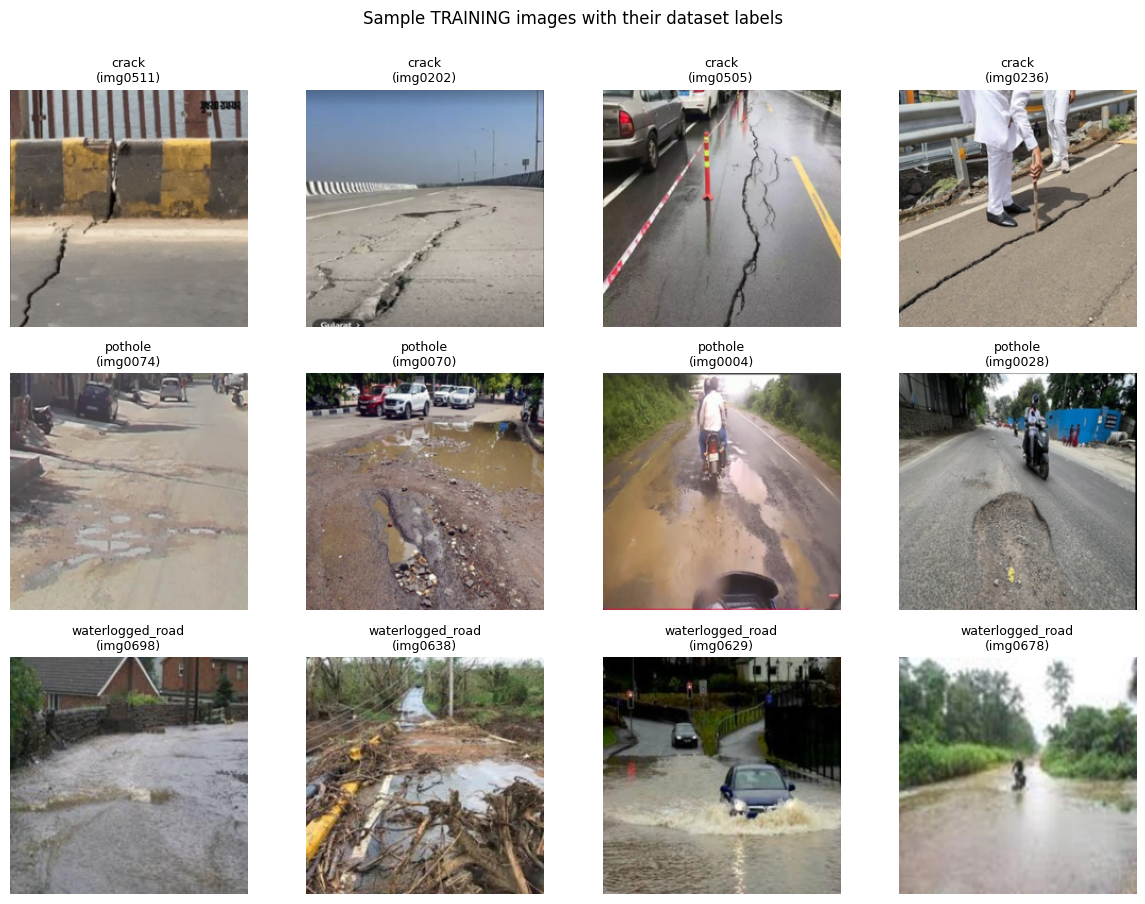

In [10]:
def load_for_display(path, size=IMG):
    """Read an image as RGB and resize to the model's input size (display only)."""
    with Image.open(path) as im:
        return im.convert("RGB").resize((size, size), Image.Resampling.BILINEAR)

def show_samples(frame, per_class=4, seed=SEED):
    rng = np.random.RandomState(seed)
    fig, axes = plt.subplots(NUM_CLASSES, per_class, figsize=(3 * per_class, 3 * NUM_CLASSES))
    axes = np.atleast_2d(axes)
    for r, cls in enumerate(CLASS_NAMES):
        sub = frame[frame["label"] == cls]
        pick = rng.choice(len(sub), size=min(per_class, len(sub)), replace=False)
        for c in range(per_class):
            ax = axes[r, c]; ax.axis("off")
            if c < len(pick):
                row = sub.iloc[pick[c]]
                ax.imshow(load_for_display(row["file"]))
                ax.set_title(f"{cls}\n({row['stem']})", fontsize=9)
    plt.suptitle("Sample TRAINING images with their dataset labels", y=1.0)
    plt.tight_layout(); plt.show()

show_samples(data[data["split"] == "train"])

## 7–8. Build the datasets and explain the preprocessing

**What happens to every image, in this exact order**

| Step | What | Why |
|---|---|---|
| 1 | `tf.io.decode_image(..., channels=3)` | Reads JPEG/PNG and forces **3 RGB channels** (greyscale files are copied into 3 channels). |
| 2 | `tf.image.resize(..., (224, 224))` | MobileNetV2 was trained on 224 × 224 inputs. Pixel values are still 0–255 here. |
| 3 | *(train only, optional)* random horizontal flip | The only augmentation; a road looks the same mirrored. |
| 4 | `mobilenet_v2.preprocess_input` | Scales pixels from 0–255 to **−1…+1**, the range MobileNetV2 expects. |

**Rule: `preprocess_input` is applied exactly once**, inside the `tf.data` pipeline. The model itself has *no* rescaling layer, and we **never** also divide by 255 — doing both would feed the network wrong values.

Order safety: the validation and test pipelines are **not shuffled**, so predictions line up with the rows of `data` in the same order.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def decode_and_resize(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # RGB, uint8
    img = tf.image.resize(img, (IMG, IMG))                               # float32, still 0..255
    img.set_shape((IMG, IMG, 3))
    return img, label

def random_flip(img, label):
    return tf.image.random_flip_left_right(img), label

def apply_mobilenet_preprocessing(img, label):
    return preprocess_input(img), label          # the ONLY place scaling happens

def make_dataset(frame, training):
    if frame.empty:
        raise ValueError("Cannot build a dataset from an empty table.")
    paths = frame["file"].astype(str).to_numpy()
    labels = frame["label_idx"].to_numpy().astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(frame), seed=CONFIG["seed"], reshuffle_each_iteration=True)
        if CONFIG["augment_train_horizontal_flip"]:
            ds = ds.map(random_flip, num_parallel_calls=AUTOTUNE)
    ds = ds.map(apply_mobilenet_preprocessing, num_parallel_calls=AUTOTUNE)
    return ds.batch(CONFIG["batch_size"]).prefetch(AUTOTUNE)

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df   = data[data["split"] == "val"].reset_index(drop=True)
test_df  = data[data["split"] == "test"].reset_index(drop=True)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)     # built now, but NOT used until Section 12
print("Rows  train/val/test:", len(train_df), len(val_df), len(test_df))

Rows  train/val/test: 207 44 44


After resize           : shape=(224, 224, 3)  min=0.0  max=254.9   (expected 0..255)
After preprocess_input : shape=(224, 224, 3)  min=-1.00  max=1.00   (expected within -1..1)
One validation batch   : images (32, 224, 224, 3) <dtype: 'float32'>, labels (32,), value range [-1.00, 1.00]


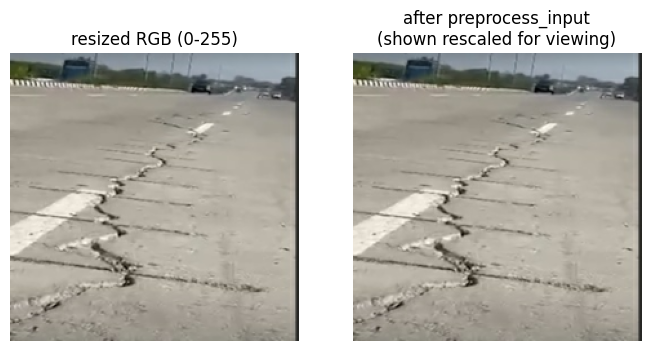

In [12]:
# ---- Prove the preprocessing is correct (uses validation images, not test) ----
raw_img, _ = decode_and_resize(str(val_df["file"].iloc[0]), 0)
pre_img, _ = apply_mobilenet_preprocessing(raw_img, 0)
print(f"After resize           : shape={tuple(raw_img.shape)}  min={raw_img.numpy().min():.1f}  max={raw_img.numpy().max():.1f}   (expected 0..255)")
print(f"After preprocess_input : shape={tuple(pre_img.shape)}  min={pre_img.numpy().min():.2f}  max={pre_img.numpy().max():.2f}   (expected within -1..1)")
xb, yb = next(iter(val_ds))
print(f"One validation batch   : images {xb.shape} {xb.dtype}, labels {yb.shape}, value range [{xb.numpy().min():.2f}, {xb.numpy().max():.2f}]")
assert -1.0001 <= float(xb.numpy().min()) and float(xb.numpy().max()) <= 1.0001, "scaling applied wrongly"

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(raw_img.numpy().astype("uint8")); ax[0].set_title("resized RGB (0-255)"); ax[0].axis("off")
ax[1].imshow(((pre_img.numpy() + 1) / 2).clip(0, 1)); ax[1].set_title("after preprocess_input\n(shown rescaled for viewing)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 9. Load and document the pretrained model

| Item | Value |
|---|---|
| Architecture | **MobileNetV2** (Sandler et al., CVPR 2018) |
| Source | `tf.keras.applications.MobileNetV2` |
| Pretrained weights | `'imagenet'` (trained on ImageNet-1k classification) |
| `include_top` | `False` — the original 1000-class layer is removed |
| Input shape | `(224, 224, 3)` |
| Base model | **Frozen** (`trainable = False`) — its weights do not change |
| Head we train | `GlobalAveragePooling2D` → `Dropout` → `Dense(num_classes, softmax)` |

**Why this works with little data:** the frozen base already knows generic visual features (edges, textures, shapes) from ImageNet. We only learn how to map those features to our three road classes.

In [13]:
def build_model(num_classes, dropout, learning_rate):
    try:
        base = tf.keras.applications.MobileNetV2(weights="imagenet", include_top=False,
                                                 input_shape=(IMG, IMG, 3))
    except Exception as e:
        raise RuntimeError(
            "Could not load the ImageNet weights (they are downloaded on first use, so Colab needs "
            f"internet access). Original error: {e}\n"
            "Do NOT continue with random weights - that would not be transfer learning.") from e
    base.trainable = False                                   # freeze the pretrained part

    inputs = tf.keras.Input(shape=(IMG, IMG, 3), name="preprocessed_image")   # already scaled to -1..1
    x = base(inputs, training=False)                         # training=False keeps BatchNorm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(dropout, name="dropout")(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="road_class")(x)
    model = tf.keras.Model(inputs, outputs, name="roadguard_mobilenetv2")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base

set_seeds()
model, base_model = build_model(NUM_CLASSES, CONFIG["dropout"], CONFIG["learning_rate"])
model.summary()
n_train_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
n_frozen_params = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
print(f"\nTrainable parameters (the head)   : {n_train_params:,}")
print(f"Frozen parameters (MobileNetV2)   : {n_frozen_params:,}")
assert base_model.trainable is False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "roadguard_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessed_image (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ road_class (Dense)              │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Trainable parameters (the head)   : 3,843
Frozen parameters (MobileNetV2)   : 2,257,984


## 10. Train the small classification head with early stopping

- Optimizer **Adam**, learning rate **0.001**, loss **sparse categorical cross-entropy**, metric **accuracy**.
- Batch size 32, at most **10 epochs**.
- **Early stopping** watches **validation loss** (patience 3) and restores the best weights. The test set is never used here.
- *Class weights* (computed from the training labels only) stop the model from favouring the largest class.

In [14]:
class_weight = None
if CONFIG["use_class_weights"]:
    w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label_idx"].to_numpy())
    class_weight = {i: float(v) for i, v in enumerate(w)}
    print("Class weights (from TRAIN only):", {IDX_TO_CLASS[i]: round(v, 3) for i, v in class_weight.items()})

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=CONFIG["early_stopping_patience"],
                                              restore_best_weights=True, verbose=1)
set_seeds()
history = model.fit(train_ds, validation_data=val_ds, epochs=CONFIG["max_epochs"],
                    callbacks=[early_stop], class_weight=class_weight, verbose=2, shuffle=False)

hist =pd.DataFrame(history.history); hist.index = hist.index + 1; hist.index.name = "epoch"
best_epoch = int(hist["val_loss"].idxmin())
print(f"\nEpochs run: {len(hist)} of max {CONFIG['max_epochs']} | best epoch by val_loss: {best_epoch}")
display(hist.round(4))

Class weights (from TRAIN only): {'crack': 0.802, 'pothole': 1.278, 'waterlogged_road': 1.03}
Epoch 1/10
7/7 - 25s - 4s/step - accuracy: 0.5604 - loss: 0.9664 - val_accuracy: 0.6364 - val_loss: 0.6933
Epoch 2/10
7/7 - 11s - 2s/step - accuracy: 0.7488 - loss: 0.6324 - val_accuracy: 0.7955 - val_loss: 0.4901
Epoch 3/10
7/7 - 19s - 3s/step - accuracy: 0.7971 - loss: 0.5185 - val_accuracy: 0.8864 - val_loss: 0.3803
Epoch 4/10
7/7 - 11s - 2s/step - accuracy: 0.8406 - loss: 0.3936 - val_accuracy: 0.8864 - val_loss: 0.3133
Epoch 5/10
7/7 - 11s - 2s/step - accuracy: 0.8792 - loss: 0.3335 - val_accuracy: 0.8864 - val_loss: 0.2749
Epoch 6/10
7/7 - 10s - 1s/step - accuracy: 0.8889 - loss: 0.2983 - val_accuracy: 0.9091 - val_loss: 0.2720
Epoch 7/10
7/7 - 11s - 2s/step - accuracy: 0.9179 - loss: 0.2693 - val_accuracy: 0.9091 - val_loss: 0.2400
Epoch 8/10
7/7 - 21s - 3s/step - accuracy: 0.9179 - loss: 0.2206 - val_accuracy: 0.9545 - val_loss: 0.2301
Epoch 9/10
7/7 - 11s - 2s/step - accuracy: 0.9324 

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.5604,0.9664,0.6364,0.6933
2,0.7488,0.6324,0.7955,0.4901
3,0.7971,0.5185,0.8864,0.3803
4,0.8406,0.3936,0.8864,0.3133
5,0.8792,0.3335,0.8864,0.2749
6,0.8889,0.2983,0.9091,0.2720
7,0.9179,0.2693,0.9091,0.2400
8,0.9179,0.2206,0.9545,0.2301
9,0.9324,0.2240,0.9091,0.2245


## 11. Plot training and validation accuracy / loss

How to read it: if training accuracy keeps rising while validation accuracy stalls or falls, the model is **over-fitting** (memorising the training images).

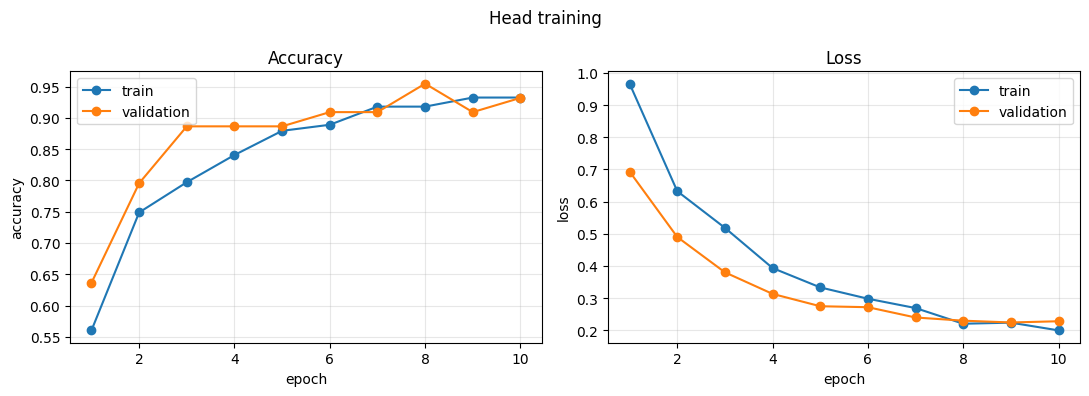

In [15]:
def plot_history(hist_df, title="Head training"):
    ep = hist_df.index
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist_df["accuracy"], marker="o", label="train")
    ax[0].plot(ep, hist_df["val_accuracy"], marker="o", label="validation")
    ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist_df["loss"], marker="o", label="train")
    ax[1].plot(ep, hist_df["val_loss"], marker="o", label="validation")
    ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist)

### (Optional) Fine-tuning — OFF by default

Fine-tuning unfreezes the last few MobileNetV2 layers and trains them with a very small learning rate. It is **optional** and is controlled by `CONFIG["run_optional_fine_tuning"]`.
If you switch it on, run it **here, before Section 12**. It uses **validation data only** to decide when to stop — the test set is not used for any model selection.

In [16]:
fine_tuned = False
if CONFIG["run_optional_fine_tuning"]:
    base_model.trainable = True
    for layer in base_model.layers[:-CONFIG["fine_tune_last_layers"]]:
        layer.trainable = False
    for layer in base_model.layers:                      # keep BatchNorm statistics fixed
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(CONFIG["fine_tune_learning_rate"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    ft_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    set_seeds()
    ft_hist = model.fit(train_ds, validation_data=val_ds, epochs=CONFIG["fine_tune_epochs"],
                        callbacks=[ft_stop], class_weight=class_weight, verbose=2, shuffle=False)
    fine_tuned = True
    ft = pd.DataFrame(ft_hist.history); ft.index = ft.index + 1; ft.index.name = "epoch"
    plot_history(ft, "Optional fine-tuning")
else:
    print("Fine-tuning skipped (CONFIG['run_optional_fine_tuning'] is False). Model = frozen base + trained head.")

Fine-tuning skipped (CONFIG['run_optional_fine_tuning'] is False). Model = frozen base + trained head.


## 12. Evaluate once on the held-out test set

This is the **first and only** time the test images are used to measure the model. We predict once and keep the predictions in a variable, so every later cell (metrics, confusion matrix, examples) uses exactly the same predictions in exactly the same order.

> Do **not** go back and change settings after looking at these results — that would turn the test set into a tuning set and the score would no longer be honest.

In [17]:
y_true = test_df["label_idx"].to_numpy()
probs = model.predict(test_ds, verbose=0)                 # test_ds is NOT shuffled -> same order as test_df
assert probs.shape == (len(test_df), NUM_CLASSES), "prediction / label count mismatch"
y_pred = probs.argmax(axis=1)
confidence = probs.max(axis=1)

test_accuracy = float(accuracy_score(y_true, y_pred))
test_loss = float(np.mean(tf.keras.losses.sparse_categorical_crossentropy(y_true, probs).numpy()))
print(f"Test images : {len(y_true)}")
print(f"Test accuracy: {test_accuracy:.4f}  ({int((y_true == y_pred).sum())} of {len(y_true)} correct)")
print(f"Test loss    : {test_loss:.4f}")

Test images : 44
Test accuracy: 0.9545  (42 of 44 correct)
Test loss    : 0.2040


## 13. Per-class precision, recall, F1-score and support

- **Precision** — of the images predicted as this class, how many really were?
- **Recall** — of the images that truly belong to this class, how many did we find?
- **F1** — the balance (harmonic mean) of precision and recall.
- **Support** — how many test images the class has (small support = unstable numbers).
- **Macro average** — plain average over classes. **Weighted average** — average weighted by support.

In [18]:
report_dict = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0, output_dict=True)
report_dict.pop("accuracy", None)
report_df = pd.DataFrame(report_dict).T[["precision", "recall", "f1-score", "support"]]
report_df["support"] = report_df["support"].astype(int)
print(f"Overall test accuracy: {test_accuracy:.4f}\n")
display(report_df.round(3))

Overall test accuracy: 0.9545



,precision,recall,f1-score,support
crack,0.947,0.947,0.947,19
pothole,0.909,0.909,0.909,11
waterlogged_road,1.000,1.000,1.000,14
macro avg,0.952,0.952,0.952,44
weighted avg,0.955,0.955,0.955,44


## 14. Confusion matrix

Rows = **true** class, columns = **predicted** class. The diagonal shows correct predictions; anything off the diagonal is a mistake of "true row mistaken for predicted column".

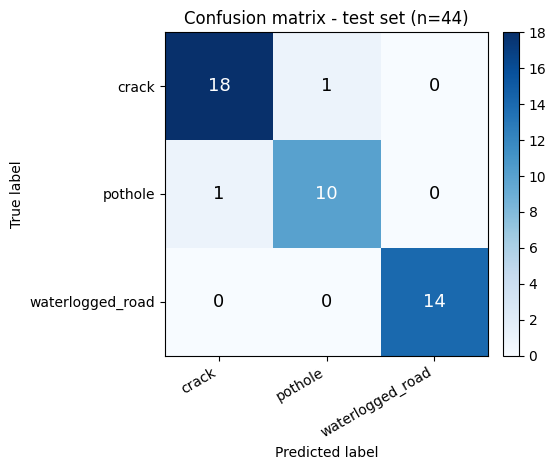

In [19]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title(f"Confusion matrix - test set (n={len(y_true)})")
thresh = cm.max() / 2 if cm.max() > 0 else 0.5
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black", fontsize=13)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); plt.tight_layout(); plt.show()

## 15. Test examples with true label, predicted label and confidence

A random sample of test images (fixed seed, not hand-picked). **Green** = correct, **red** = wrong. *Confidence* is the model's softmax probability for its predicted class; it is **not** a guarantee of being right.

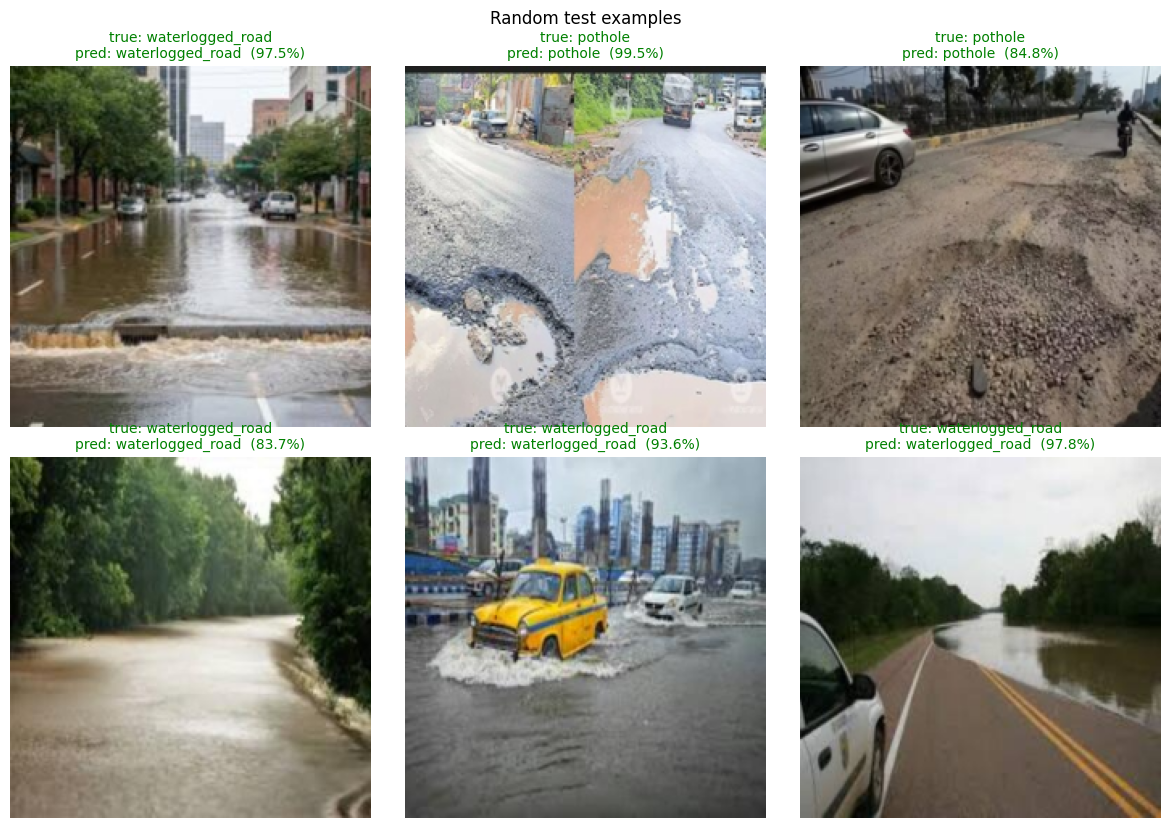

In [20]:
def show_examples(indices, title, ncols=3):
    indices = list(indices)
    if not indices:
        print(f"{title}: nothing to show."); return
    nrows = int(np.ceil(len(indices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(load_for_display(test_df["file"].iloc[i]))
        ok = y_true[i] == y_pred[i]
        ax.set_title(f"true: {IDX_TO_CLASS[int(y_true[i])]}\npred: {IDX_TO_CLASS[int(y_pred[i])]}  ({confidence[i]*100:.1f}%)",
                     fontsize=10, color="green" if ok else "red")
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.RandomState(CONFIG["seed"])
n_show = min(6, len(test_df))
if n_show < 6:
    print(f"Only {len(test_df)} test images exist, showing all of them.")
show_examples(rng.choice(len(test_df), size=n_show, replace=False), "Random test examples")

## 16. Misclassified test examples and plausible error causes

Misclassified test images: 2 of 44

Which classes get confused (true -> predicted):


,true,predicted,count
0,crack,pothole,1
1,pothole,crack,1


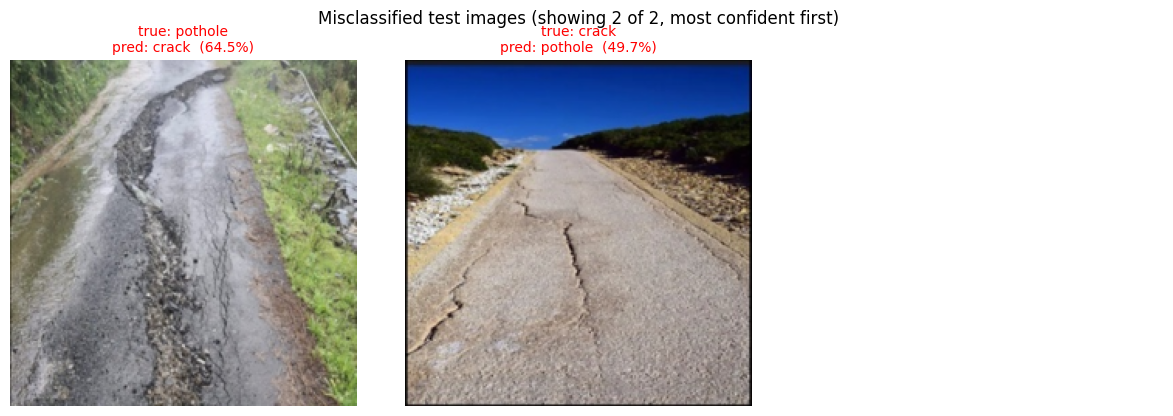

In [21]:
wrong = np.where(y_true != y_pred)[0]
print(f"Misclassified test images: {len(wrong)} of {len(y_true)}")
if len(wrong) == 0:
    print("The model made no mistakes on this small test set. That does NOT prove it is perfect - "
          "the test set is tiny and comes from the same dataset.")
else:
    wrong_sorted = wrong[np.argsort(-confidence[wrong])]            # most confident mistakes first
    pairs = (pd.DataFrame({"true": [IDX_TO_CLASS[int(y_true[i])] for i in wrong],
                           "predicted": [IDX_TO_CLASS[int(y_pred[i])] for i in wrong]})
             .value_counts().rename("count").reset_index())
    print("\nWhich classes get confused (true -> predicted):")
    display(pairs)
    show_examples(wrong_sorted[:9], f"Misclassified test images (showing {min(9, len(wrong))} of {len(wrong)}, most confident first)")
    if len(wrong) > 9:
        print(f"{len(wrong) - 9} more misclassified images are not shown.")

### Discussion of plausible error causes (write your own after looking at your plots)

The points below are **hypotheses to check against your actual wrong predictions** — they are not findings. Keep only the ones your images support, and delete the rest.

- **Cracks vs potholes:** a badly cracked or broken patch can look like a shallow pothole, and a pothole has cracks around it.
- **Water hiding damage:** a waterlogged road may hide potholes beneath the water, so the "true" class depends on what the photographer meant.
- **Small data:** a few hundred training images and a test set of a few dozen images means a single image changes the scores noticeably.
- **Different image sources:** news photos, Google Maps frames and video screenshots differ in camera, angle and quality, which can confuse a model trained on few examples.
- **Low resolution:** the images are only 256 × 256, so thin cracks lose detail when resized to 224 × 224.
- **Label noise:** with only one annotator per image, some labels may be debatable.
- **Source shortcut:** waterlogged-road photos all share one source, so the model may recognise that source's photo style; check whether errors involving this class fit this explanation.

## 17. Save the model, class mapping and configuration

Everything needed to reproduce and reuse the run is written to the `outputs/` folder.

In [22]:
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

model.save(OUT / "roadguard_mobilenetv2.keras")
(OUT / "class_mapping.json").write_text(json.dumps(
    {"class_to_idx": CLASS_TO_IDX, "idx_to_class": {str(k): v for k, v in IDX_TO_CLASS.items()}}, indent=2))

run_config = {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()}
run_config.update(
    model="MobileNetV2 (tf.keras.applications), weights='imagenet', include_top=False, input_shape=(224,224,3), base frozen",
    head="GlobalAveragePooling2D -> Dropout -> Dense(softmax)",
    preprocessing="tf.io.decode_image(channels=3) -> tf.image.resize(224,224) -> mobilenet_v2.preprocess_input (once, range -1..1)",
    optimizer="Adam", loss="sparse_categorical_crossentropy",
    fine_tuned=fine_tuned, epochs_run=int(len(hist)), best_epoch_by_val_loss=best_epoch,
    train_images=int(len(train_df)), val_images=int(len(val_df)), test_images=int(len(test_df)),
    official_splits_had_leakage=bool(OFFICIAL_SPLITS_LEAK),
    versions=dict(python=platform.python_version(), tensorflow=tf.__version__, numpy=np.__version__, pandas=pd.__version__),
    test_accuracy=test_accuracy, test_loss=test_loss)
(OUT / "config.json").write_text(json.dumps(run_config, indent=2, default=str))

data.drop(columns=["file"]).assign(file=data["file"].astype(str)).to_csv(OUT / "split_manifest.csv", index=False)
exclusion_df.to_csv(OUT / "excluded_images.csv", index=False)
pd.DataFrame({"stem": test_df["stem"], "true": [IDX_TO_CLASS[int(i)] for i in y_true],
              "predicted": [IDX_TO_CLASS[int(i)] for i in y_pred], "confidence": confidence.round(4)}
             ).to_csv(OUT / "test_predictions.csv", index=False)

# ---- Reload check: the saved file must give the same predictions ----
reloaded = tf.keras.models.load_model(OUT / "roadguard_mobilenetv2.keras")
xb, _ = next(iter(test_ds))
same = np.allclose(model.predict(xb, verbose=0), reloaded.predict(xb, verbose=0), atol=1e-5)
print("Saved files:", sorted(p.name for p in OUT.iterdir()))
print("Reloaded model reproduces predictions on one test batch:", same)
assert same, "Saved model does not match the trained model"

Saved files: ['class_mapping.json', 'config.json', 'excluded_images.csv', 'roadguard_mobilenetv2.keras', 'split_manifest.csv', 'test_predictions.csv']
Reloaded model reproduces predictions on one test batch: True


In [23]:
# Optional (Colab only): download the outputs as one ZIP.
import shutil
shutil.make_archive("roadguard_outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("roadguard_outputs.zip")
except ImportError:
    print("Not running in Colab - the ZIP is in the working folder: roadguard_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Conclusion, limitations, reproducibility and references

### Auto-generated results summary
The next cell prints a summary from the numbers your run actually produced. Copy it into your report.

In [24]:
print("=== RESULTS SUMMARY (generated from this run) ===")
print(f"Classes                    : {CLASS_NAMES}")
print(f"Images used train/val/test : {len(train_df)} / {len(val_df)} / {len(test_df)}")
print(f"Excluded images (total)    : {len(exclusion_df)}")
print(f"Official splits leaked?    : {OFFICIAL_SPLITS_LEAK}  -> own duplicate-aware split used")
print(f"Epochs run (max {CONFIG['max_epochs']})       : {len(hist)}  (best epoch {best_epoch} by validation loss)")
print(f"Fine-tuning used           : {fine_tuned}")
print(f"Best val accuracy          : {hist['val_accuracy'].max():.4f}")
print(f"TEST accuracy              : {test_accuracy:.4f}  ({int((y_true == y_pred).sum())}/{len(y_true)})")
print(f"Macro F1 / Weighted F1     : {report_df.loc['macro avg','f1-score']:.4f} / {report_df.loc['weighted avg','f1-score']:.4f}")
print(f"Misclassified test images  : {len(wrong)}")

=== RESULTS SUMMARY (generated from this run) ===
Classes                    : ['crack', 'pothole', 'waterlogged_road']
Images used train/val/test : 207 / 44 / 44
Excluded images (total)    : 305
Official splits leaked?    : True  -> own duplicate-aware split used
Epochs run (max 10)       : 10  (best epoch 9 by validation loss)
Fine-tuning used           : False
Best val accuracy          : 0.9545
TEST accuracy              : 0.9545  (42/44)
Macro F1 / Weighted F1     : 0.9522 / 0.9545
Misclassified test images  : 2


### Conclusion (write after running)
State in 3–4 sentences: the test accuracy and macro-F1 you obtained, which class was easiest and which was hardest, and what the confusion matrix shows. Do **not** claim the model will work on all Indian roads.

### Limitations
- Very small dataset after removing duplicates; the test set has only a few dozen images, so scores are **noisy** and could change noticeably with a different random split.
- Only three classes; the other three IRDID classes are incomplete in the repository.
- The duplicate detector finds identical and near-identical pictures, but **not** different photos of the same road or different frames of the same video; source-level similarity between splits remains possible.
- The waterlogged-road class comes from a single source, so class and photo style are partly confounded (see the source table in Section 5).
- Labels come from the dataset authors (one annotator per image); no independent verification was done.
- Classification only: the model says *what kind* of damage the whole picture shows, not *where* it is or how severe it is.
- Results apply to this dataset and this split only; no claim is made about real-world deployment.

### Reproducibility notes
- Fixed seed (`42`) for Python, NumPy, TensorFlow and the data split; exact GPU results can still differ slightly between runs/hardware.
- `outputs/config.json` records every setting and library version; `outputs/split_manifest.csv` records which image went to which split; `outputs/excluded_images.csv` records every exclusion and why.
- Dataset is fetched from the live GitHub repository (`git clone --depth 1`), so if the authors change it, counts may change — the printed audit in Sections 4–5 shows what was actually used.

### References
1. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks.* IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR), pp. 4510–4520. arXiv:1801.04381.
2. Russakovsky, O., et al. (2015). *ImageNet Large Scale Visual Recognition Challenge.* International Journal of Computer Vision, 115(3), 211–252.
3. Keras documentation — `tf.keras.applications.MobileNetV2` and `mobilenet_v2.preprocess_input`: https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2
4. Indian Road Damage & Infrastructure Dataset Contributors (2026). *IRDID.* https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset (CC BY 4.0, https://creativecommons.org/licenses/by/4.0/).
5. Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research, 12, 2825–2830.